# Multisample fitting study

When does fitting one coefficient vector across independent trajectories help EPDE recover an equation? The study compares separate fits averaged after regression (`mean`) with a fit that shares coefficients (`joint`).

Use a Python kernel with EPDE, NumPy, pandas, SciPy, and Matplotlib installed. Keep the accompanying data beside the notebook. Run all cells to fit the small example and regenerate the tables and figures from the recorded trials.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import t as student_t

data_path = Path("research_data.json")
if not data_path.is_file():
    data_path = Path("projects/multisample/notebooks") / data_path
with data_path.open(encoding="utf-8") as stream:
    data = json.load(stream)

runs = pd.DataFrame(data["runs"])
reference = pd.DataFrame(data["reference_mean"])
fronts = pd.DataFrame(data["fronts"])
runs["law_recovered"] = runs["exact_support"].eq(True) & runs["coefficient_error"].lt(0.10)
runs["exact_support"] = runs["exact_support"].eq(True).where(runs["exact_support"].notna())

## Why pool trajectories?

For a single spatial mode $k$, $u_{xx}=-k^2u$. A fit on that record alone cannot distinguish the coefficients of $u$ and $u_{xx}$. With two different modes the pooled design has full rank. The joint fit minimizes $\sum_s w_s\lVert y_s-X_s\beta\rVert_2^2$ for one $\beta$. Here each record gets equal total weight.

In [2]:
from epde.operators.common.multisample import joint_subset_table

blocks = []
local = []
for k, n in [(1, 60), (2, 90)]:
    t = np.linspace(0, 2, n)
    x = np.linspace(0.3, 2.8, n)
    u = np.exp(-(0.2 + 0.1 * k**2) * t) * np.sin(k * x)
    X = np.column_stack([u, -k**2 * u])
    y = X @ [-0.2, 0.1]
    blocks.append((k, X, y, np.ones(n)))
    slope = np.linalg.lstsq(X[:, :1], y, rcond=None)[0][0]
    local.append({"mode number": k, "design rank": np.linalg.matrix_rank(X), "slope": slope})

_, _, _, coefficients, full_rank = joint_subset_table(
    blocks, discrepancy="l2_relative", subsets=[0b011], weighting="samples"
)
display(pd.DataFrame(local).round(3))
print(f"Mean slope for u: {np.mean([row['slope'] for row in local]):.3f}")
print(f"Joint coefficients for u and u_xx: {coefficients[0, :2].round(3)}")
print(f"Full rank on the pooled design: {bool(full_rank[0])}")

,mode number,design rank,slope
0,1,1,-0.3
1,2,1,-0.6


Mean slope for u: -0.450
Joint coefficients for u and u_xx: [-0.2  0.1]
Full rank on the pooled design: True


## Regression coverage

The recorded checks cover grids, data copies, cached values, custom tokens, and joint fits. The reference implementation could not collect tests for some unavailable features, so the totals differ. The detailed table records passed cases over collected cases.

In [3]:
summary = pd.DataFrame(data["regression_summary"]).set_index("configuration")
display(summary.rename(columns=lambda name: name.replace("_", " ").capitalize()))
with pd.option_context("display.max_rows", None, "display.max_colwidth", 90):
    display(pd.DataFrame(data["regression_checks"]).set_index("area"))

,Passed,Feature unavailable,Validation failure,Other failure
configuration,,,,
Reference,9,51,23,55
Multisample,157,0,0,0


,check,reference,multisample
area,,,
Configuration,joint configuration is explicit and serializable,0/1 (feature unavailable),1/1
Configuration,invalid multisample config is refused,2/4 (validation failure),4/4
Input validation,empty sample list is rejected before build,0/1 (validation failure),1/1
Input validation,records must have the same variables,0/2 (validation failure),2/2
Input validation,variable order cannot silently change derivative ids,0/1 (validation failure),1/1
Input validation,repeated sample is not silently deduplicated,0/1 (validation failure),1/1
Input validation,invalid field is rejected with sample context,0/3 (validation failure),3/3
Input validation,conflicting domain id cannot reuse old coordinates,0/1 (validation failure),1/1
Multisample API,multisample adapter uses independent fd derivatives,0/1 (feature unavailable),1/1


## Benchmark design

The three stages are fitting a supplied structure, selecting from supplied terms, and evolutionary discovery. Discovery uses five seeds, a requested population of eight, and four epochs. Gaussian noise is scaled to the standard deviation of each field. Strong-form fits use exact derivatives or finite differences, with a smoothing trial. Weak-form fits use test-function integrals.

| Task | Reference equation or control |
| --- | --- |
| Affine | $u_t = 0.4 - 0.7u$ |
| Logistic | $u_t = 1.2u - 0.6u^2$ |
| Coupled system | $u_t = -0.2u + v$, $v_t = -u - 0.2v$ |
| Reaction–diffusion | $u_t = -0.2u + 0.1u_{xx}$, with one or two modes per record |
| Heat | $u_t = 0.1u_{xx}$ |
| Advection–diffusion | $u_t = -0.5u_x + 0.1u_{xx}$ |
| Overdamped oscillator | $u_{tt} = -2u - 3u_t$, one exponential per training record |
| Underdamped oscillator | $u_{tt} = -4u - 0.3u_t$ |
| Wave | $u_{tt} = 0.64u_{xx}$ |
| Klein–Gordon | $u_{tt} = 0.64u_{xx} - u$ |
| Conflicting laws | $u_t = -0.4u$ and $u_t = -u$ on different records |
| Sampling density | $u_{tt} = -u$ and $u_{tt} = -4u$ on different grids |
| Robot heading | $u_t=-\omega v$, $v_t=\omega u$ |

A structure is correct when every equation has the reference term set. A law is recovered when its structure is correct and its largest relative coefficient error is below 10%. Held-out residuals are relative $L_2$ errors on independent records. No-candidate runs stay in the denominators.

In [4]:
display(pd.crosstab([runs["stage"], runs["mode"]], runs["status"]))

status            no_candidate   ok
stage      mode                    
assignment joint             0    2
           mean              0    2
discovery  joint             0  190
           mean              0  190
fixed      joint             0   28
           mean              3   19

## Mean-mode compatibility

Compare each recorded reference run with the mean fit under the same task, search settings, and seed. Compare both the run status and the selected equation.

In [5]:
pair_keys = [
    "scenario", "stage", "derivatives", "noise", "seed", "mode", "weighting",
    "form", "density", "right_part", "population", "epochs",
]
pairs = reference.merge(
    runs[runs["mode"].eq("mean")], on=pair_keys, suffixes=("_reference", "_mean"),
    how="left", indicator=True, validate="one_to_one",
)
matched = pairs["_merge"].eq("both")
different = matched & (
    pairs["status_reference"].ne(pairs["status_mean"])
    | pairs["equation_reference"].ne(pairs["equation_mean"])
)
display(pd.Series({
    "Matched settings": int(matched.sum()),
    "Matching status and equation": int((matched & ~different).sum()),
    "Matched runs without a candidate": int((matched & pairs["status_mean"].eq("no_candidate")).sum()),
    "Unmatched settings": int((~matched).sum()),
}).to_frame("Runs"))
if different.any():
    display(pairs.loc[different, pair_keys + ["status_reference", "status_mean",
                                             "equation_reference", "equation_mean"]])

,Runs
Matched settings,214
Matching status and equation,214
Matched runs without a candidate,3
Unmatched settings,0


## Discovery with first time derivatives

Compare the selected structures and the held-out residuals for plain search. The mixed-mode reaction–diffusion control has enough information within each record to identify both terms.

In [6]:
case_names = {
    "advection_diffusion": "Advection–diffusion", "affine": "Affine", "coupled": "Coupled",
    "heat": "Heat", "klein_gordon": "Klein–Gordon", "logistic": "Logistic",
    "oscillator": "Underdamped oscillator", "oscillator_modes": "Overdamped oscillator",
    "reaction_diffusion": "Reaction–diffusion", "reaction_diffusion_rich": "Mixed-mode reaction–diffusion",
    "robot_heading": "Robot heading", "wave": "Wave",
}
second_order = ["oscillator_modes", "oscillator", "wave", "klein_gordon"]

def condition(row):
    if row["derivatives"] == "analytic":
        return "Exact derivatives"
    if row["noise"] == 0:
        return "Finite differences"
    form = "weak" if row["form"] == "weak" else "strong"
    return f"{row['noise']:.0%} noise, {form}"

def label_runs(trials):
    return trials.assign(task=trials["scenario"].map(case_names),
                         condition=trials.apply(condition, axis=1))

def summarize(trials, groups=("task", "condition", "mode")):
    return trials.groupby(list(groups)).agg(
        runs=("run", "size"), correct=("exact_support", "sum"),
        on_front=("exact_on_front", "sum"), recovered=("law_recovered", "sum"),
        coefficient_error=("coefficient_error", "median"),
        holdout_residual=("holdout_residual", "median"),
    )

def show_summary(table):
    table = table.copy()
    count_columns = ["runs", "correct", "on_front", "recovered"]
    table[count_columns] = table[count_columns].astype(int)
    with pd.option_context("display.float_format", "{:.3g}".format):
        display(table)

plain = runs.loc[
    runs["stage"].eq("discovery") & runs["right_part"].eq("plain")
    & runs["derivatives"].ne("poly") & runs["scenario"].ne("robot_heading")
]
first = label_runs(plain.loc[~plain["scenario"].isin(second_order)])
second = label_runs(plain.loc[plain["scenario"].isin(second_order)])
first_summary = summarize(first)
show_summary(first_summary)

runs  correct  \
task                          condition         mode                   
Advection–diffusion           Exact derivatives joint     5        5   
                                                mean      5        5   
Coupled                       1% noise, strong  joint     5        5   
                                                mean      5        5   
                              Exact derivatives joint     5        5   
                                                mean      5        5   
Heat                          Exact derivatives joint     5        5   
                                                mean      5        5   
Logistic                      1% noise, strong  joint     5        5   
                                                mean      5        5   
                              1% noise, weak    joint     5        5   
                                                mean      5        5   
                              Exact derivatives joint     5        5   
                                                mean      5        5   
Mixed-mode reaction–diffusion Exact derivatives joint     5        5   
                                                mean      5        5   
Reaction–diffusion            1% noise, strong  joint     5        5   
                                                mean      5        0   
                              1% noise, weak    joint     5        5   
                                                mean      5        0   
                              5% noise, strong  joint     5        5   
                                                mean      5        0   
                              Exact derivatives joint     5        5   
                                                mean      5        0   

                                                       on_front  recovered  \
task                          condition         mode                         
Advection–diffusion           Exact derivatives joint         5          5   
                                                mean          5          5   
Coupled                       1% noise, strong  joint         5          5   
                                                mean          5          5   
                              Exact derivatives joint         5          5   
                                                mean          5          5   
Heat                          Exact derivatives joint         5          5   
                                                mean          5          5   
Logistic                      1% noise, strong  joint         5          5   
                                                mean          5          5   
                              1% noise, weak    joint         5          5   
                                                mean          5          5   
                              Exact derivatives joint         5          5   
                                                mean          5          5   
Mixed-mode reaction–diffusion Exact derivatives joint         5          5   
                                                mean          5          5   
Reaction–diffusion            1% noise, strong  joint         5          0   
                                                mean          0          0   
                              1% noise, weak    joint         5          5   
                                                mean          0          0   
                              5% noise, strong  joint         5          0   
                                                mean          0          0   
                              Exact derivatives joint         5          5   
                                                mean          0          0   

                                                       coefficient_error  \
task                          condition         mode                       
A

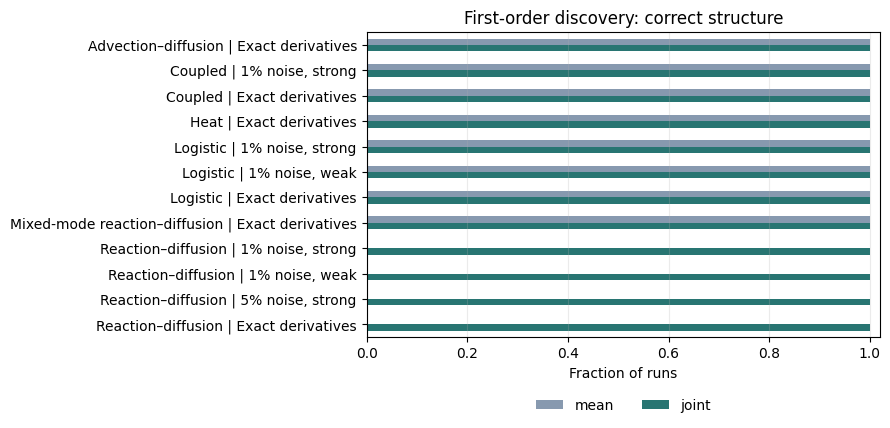

In [7]:
colors = {"mean": "#8799af", "joint": "#287572"}

def plot_recovery(table, metric, title):
    rates = (table[metric] / table["runs"]).unstack("mode")[["mean", "joint"]]
    rates.index = [f"{task} | {setting}" for task, setting in rates.index]
    ax = rates.plot.barh(color=[colors["mean"], colors["joint"]],
                         figsize=(9, max(3, 0.37 * len(rates))))
    ax.set(xlabel="Fraction of runs", ylabel="", xlim=(0, 1.02), title=title)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.25)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncols=2)
    plt.tight_layout()
    plt.show()

plot_recovery(first_summary, "correct", "First-order discovery: correct structure")

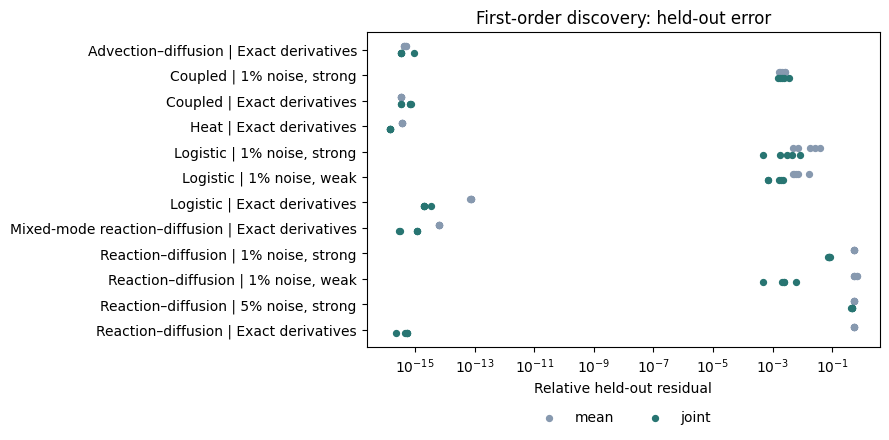

In [8]:
groups = list(first_summary.index.droplevel("mode").unique())
fig, ax = plt.subplots(figsize=(9, max(3, 0.38 * len(groups))))
for mode, offset in [("mean", -0.13), ("joint", 0.13)]:
    for index, (task, setting) in enumerate(groups):
        scores = first.loc[
            first["task"].eq(task) & first["condition"].eq(setting) & first["mode"].eq(mode),
            "holdout_residual",
        ].dropna()
        ax.scatter(scores, np.full(len(scores), index + offset), color=colors[mode], s=18,
                   label=mode if index == 0 else None)
ax.set(xscale="log", xlabel="Relative held-out residual", title="First-order discovery: held-out error")
ax.set_yticks(range(len(groups)), [f"{task} | {setting}" for task, setting in groups])
ax.invert_yaxis()
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncols=2)
plt.tight_layout()
plt.show()

In the single-mode reaction–diffusion runs, joint fitting found the correct structure in all five seeds in each condition. Under 1% strong-form noise, its median coefficient error was about 13%. The weak form reduced it to 0.5%.

## Discovery with second time derivatives

The overdamped oscillator, wave, and Klein–Gordon records each use one mode. The underdamped oscillator is a control. Compare the exact-derivative runs with 1% noise in strong and weak forms.

runs  correct  on_front  \
task                   condition         mode                             
Klein–Gordon           1% noise, strong  joint     5        5         5   
                                         mean      5        5         5   
                       1% noise, weak    joint     5        5         5   
                                         mean      5        2         2   
                       Exact derivatives joint     5        5         5   
                                         mean      5        0         0   
Overdamped oscillator  1% noise, strong  joint     5        0         5   
                                         mean      5        0         5   
                       1% noise, weak    joint     5        3         5   
                                         mean      5        1         3   
                       Exact derivatives joint     5        5         5   
                                         mean      5        0         0   
Underdamped oscillator 1% noise, strong  joint     5        5         5   
                                         mean      5        5         5   
                       1% noise, weak    joint     5        5         5   
                                         mean      5        5         5   
                       Exact derivatives joint     5        5         5   
                                         mean      5        5         5   
Wave                   1% noise, strong  joint     5        4         5   
                                         mean      5        5         5   
                       1% noise, weak    joint     5        4         5   
                                         mean      5        5         5   
                       Exact derivatives joint     5        5         5   
                                         mean      5        5         5   

                                                recovered  coefficient_error  \
task                   condition         mode                                  
Klein–Gordon           1% noise, strong  joint          5               0.05   
                                         mean           1              0.113   
                       1% noise, weak    joint          5            0.00108   
                                         mean           0               1.19   
                       Exact derivatives joint          5           2.26e-15   
                                         mean           0              0.993   
Overdamped oscillator  1% noise, strong  joint          0                NaN   
                                         mean           0                NaN   
                       1% noise, weak    joint          3             0.0114   
                                         mean           0              0.693   
                       Exact derivatives joint          5           5.23e-16   
                                         mean           0              0.693   
Underdamped oscillator 1% noise, strong  joint          5            0.00962   
                                         mean           5            0.00797   
                       1% noise, weak    joint          5           0.000364   
                                         mean           5           0.000338   
                       Exact derivatives joint          5           2.22e-16   
                                         mean           5           2.23e-16   
Wave                   1% noise, strong  joint          4              0.025   
                                         mean           3             0.0979   
                       1% noise, weak    joint          4            0.00063   
                                         mean           5            0.00169   
                       Exact derivatives joint          5           6.94e-16   
                                         mean           5           1.91e-15   

                

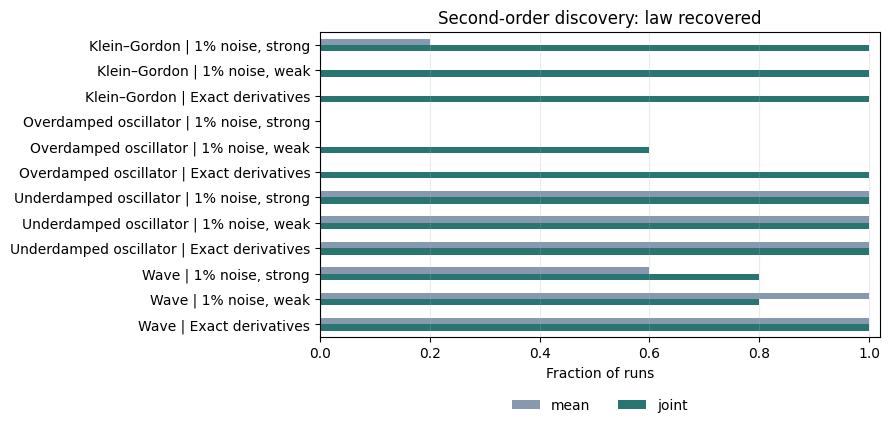

In [9]:
second_summary = summarize(second)
show_summary(second_summary)
plot_recovery(second_summary, "recovered", "Second-order discovery: law recovered")

In [10]:
example = second.loc[
    second["seed"].eq(0) & second["derivatives"].eq("analytic"),
    ["task", "mode", "law_recovered", "equation"],
]
display(example.set_index(["task", "mode"]))

law_recovered  \
task                   mode                   
Overdamped oscillator  mean           False   
                       joint           True   
Underdamped oscillator mean            True   
                       joint           True   
Wave                   mean            True   
                       joint           True   
Klein–Gordon           mean           False   
                       joint           True   

                                                                       equation  
task                   mode                                                      
Overdamped oscillator  mean   -1.5 * du/dx0{power: 1.0} = d^2u/dx0^2{power: ...  
                       joint  -0.3333333333333332 * d^2u/dx0^2{power: 1.0} +...  
Underdamped oscillator mean   -4.000000000000001 * u{power: 1.0} + -0.300000...  
                       joint  -3.9999999999999973 * u{power: 1.0} + -0.29999...  
Wave                   mean   0.6399999999999975 * d^2u/dx1^2{power: 1.0} = ...  
                       joint  0.6399999999999996 * d^2u/dx1^2{power: 1.0} = ...  
Klein–Gordon           mean   1.265000000000002 * d^2u/dx1^2{power: 1.0} = d...  
                       joint  0.6399999999999992 * d^2u/dx1^2{power: 1.0} + ...

With exact derivatives, both modes recovered the wave equation and the underdamped oscillator in all five seeds. Joint fitting recovered the overdamped oscillator and Klein–Gordon in five out of five seeds, compared with zero for mean fitting. At 1% noise, the joint weak form recovered the overdamped oscillator in three out of five seeds.

## Supplied terms and controls

Fixed fits test coefficient estimation with the structure supplied. Assignment tests selection among supplied terms. Two controls check what happens when records disagree about the law or when one grid is refined.

In [11]:
supplied = runs.loc[runs["stage"].isin(["fixed", "assignment"])]
rows = ["scenario", "stage", "derivatives", "noise", "mode", "weighting", "density", "form",
        "status", "exact_support", "coefficient_error", "holdout_residual"]
with pd.option_context("display.max_rows", None, "display.float_format", "{:.3g}".format):
    display(supplied[rows].sort_values(["stage", "scenario", "derivatives", "noise", "mode"]))

controls = pd.DataFrame(data["controls"])
display(controls.loc[controls["control"].eq("contradictory_laws"),
                     ["mode", "maximum_clean_training_residual", "cannot_fit_both_exactly"]])
display(controls.loc[controls["control"].eq("sampling_density"),
                     ["weighting", "coarse_coefficient", "refined_coefficient",
                      "absolute_change", "expected_coarse", "expected_refined"]].round(6))

,scenario,stage,derivatives,noise,mode,weighting,density,form,status,exact_support,coefficient_error,holdout_residual
93,logistic,assignment,analytic,0,joint,samples,None,strong,ok,True,1.11e-15,1.52e-15
92,logistic,assignment,analytic,0,mean,samples,None,strong,ok,True,4.55e-14,7.24e-14
96,reaction_diffusion,assignment,analytic,0,joint,samples,None,strong,ok,False,0.989,0.501
95,reaction_diffusion,assignment,analytic,0,mean,samples,None,strong,ok,False,1.05,0.657
111,advection_diffusion,fixed,analytic,0,joint,samples,None,strong,ok,True,2.43e-16,3.36e-16
110,advection_diffusion,fixed,analytic,0,mean,samples,None,strong,ok,True,2.19e-16,4.39e-16
1,affine,fixed,analytic,0,joint,samples,None,strong,ok,True,1.54e-16,2.23e-16
0,affine,fixed,analytic,0,mean,samples,None,strong,ok,True,1.38e-15,3.08e-15
27,contradictory,fixed,analytic,0,joint,samples,None,strong,ok,NaN,NaN,0.169
26,contradictory,fixed,analytic,0,mean,samples,None,strong,ok,NaN,NaN,1.73e-16


,mode,maximum_clean_training_residual,cannot_fit_both_exactly
0,mean,0.750000,True
1,joint,0.453694,True


,weighting,coarse_coefficient,refined_coefficient,absolute_change,expected_coarse,expected_refined
2,samples,-2.5,-2.5,0.0,-2.5,-2.5
3,points,-2.5,-3.4,0.9,-2.5,-3.4


## Joint fitting in repair mode

Joint VWSR sums weighted Gram matrices and averages the per-record instability scores. The linear-dependence check uses the pooled design. The window metrics `cv` and `vcoef` are unavailable in joint repair.

In [12]:
repair = label_runs(runs.loc[runs["stage"].eq("discovery") & runs["right_part"].eq("repair")])
show_summary(summarize(repair))
examples = repair.loc[repair["seed"].eq(0),
                      ["task", "condition", "mode", "law_recovered", "equation"]]
with pd.option_context("display.max_colwidth", 100):
    display(examples.set_index(["task", "condition", "mode"]))

runs  correct  on_front  \
task                  condition         mode                             
Klein–Gordon          1% noise, strong  joint     5        0         0   
                                        mean      5        3         3   
                      Exact derivatives joint     5        5         5   
                                        mean      5        0         0   
Logistic              1% noise, strong  joint     5        3         3   
                                        mean      5        3         3   
                      Exact derivatives joint     5        5         5   
                                        mean      5        5         5   
Overdamped oscillator 1% noise, strong  joint     5        0         2   
                                        mean      5        0         1   
                      Exact derivatives joint     5        5         5   
                                        mean      5        0         0   
Reaction–diffusion    1% noise, strong  joint     5        0         0   
                                        mean      5        0         0   
                      Exact derivatives joint     5        5         5   
                                        mean      5        0         0   

                                               recovered  coefficient_error  \
task                  condition         mode                                  
Klein–Gordon          1% noise, strong  joint          0              0.881   
                                        mean           0              0.625   
                      Exact derivatives joint          5           1.82e-15   
                                        mean           0              0.947   
Logistic              1% noise, strong  joint          3            0.00259   
                                        mean           0              0.328   
                      Exact derivatives joint          5           4.96e-15   
                                        mean           5           4.62e-14   
Overdamped oscillator 1% noise, strong  joint          0                NaN   
                                        mean           0                NaN   
                      Exact derivatives joint          5           6.07e-16   
                                        mean           0              0.693   
Reaction–diffusion    1% noise, strong  joint          0              0.878   
                                        mean           0                1.2   
                      Exact derivatives joint          5           9.04e-16   
                                        mean           0                  1   

                                               holdout_residual  
task                  condition         mode                     
Klein–Gordon          1% noise, strong  joint             0.297  
                                        mean              0.286  
                      Exact derivatives joint          1.42e-15  
                                        mean              0.503  
Logistic              1% noise, strong  joint           0.00454  
                                        mean              0.579  
                      Exact derivatives joint          6.22e-15  
                                        mean           7.45e-14  
Overdamped oscillator 1% noise, strong  joint             0.766  
                                        mean              0.713  
                      Exact derivatives joint          9.95e-16  
                                        mean               0.94  
Reaction–diffusion    1% noise, strong  joint             0.525  
                                        mean              0.552  
                      Exact derivatives joint          4.17e-16  
                                        mean              0.528

law_recovered  \
task                  condition         mode                   
Logistic              Exact derivatives mean            True   
                                        joint           True   
                      1% noise, strong  mean           False   
                                        joint           True   
Reaction–diffusion    Exact derivatives mean           False   
                                        joint           True   
                      1% noise, strong  mean           False   
                                        joint          False   
Overdamped oscillator Exact derivatives mean           False   
                                        joint           True   
                      1% noise, strong  mean           False   
                                        joint          False   
Klein–Gordon          Exact derivatives mean           False   
                                        joint           True   
                      1% noise, strong  mean           False   
                                        joint          False   

                                                                                                                                          equation  
task                  condition         mode                                                                                                        
Logistic              Exact derivatives mean         -0.6000000000000257 * u{power: 2.0} + 1.2000000000000564 * u{power: 1.0} = du/dx0{power: 1.0}  
                                        joint         -0.6000000000000029 * u{power: 2.0} + 1.200000000000006 * u{power: 1.0} = du/dx0{power: 1.0}  
                      1% noise, strong  mean        -0.41979467284965327 * u{power: 2.0} + 0.7996206927119492 * u{power: 1.0} = du/dx0{power: 1.0}  
                                        joint         -0.601521790402743 * u{power: 2.0} + 1.2031173230038317 * u{power: 1.0} = du/dx0{power: 1.0}  
Reaction–diffusion    Exact derivatives mean                                       5.000000000000009 * du/dx0{power: 1.0} = d^2u/dx1^2{power: 1.0}  
                                        joint  0.10000000000000006 * d^2u/dx1^2{power: 1.0} + -0.19999999999999982 * u{power: 1.0} = du/dx0{pow...  
                      1% noise, strong  mean                                              -0.4488737590055957 * u{power: 1.0} = du/dx0{power: 1.0}  
                                        joint                                             -0.3679031536172807 * u{power: 1.0} = du/dx0{power: 1.0}  
Overdamped oscillator Exact derivatives mean                                                    -1.5 * du/dx0{power: 1.0} = d^2u/dx0^2{power: 1.0}  
                                        joint  -0.3333333333333334 * d^2u/dx0^2{power: 1.0} + -0.6666666666666662 * u{power: 1.0} = du/dx0{powe...  
                      1% noise, strong  mean                                               -1.497391748842912 * u{power: 1.0} = du/dx0{power: 1.0}  
                                        joint                                             -1.5995537692791737 * u{power: 1.0} = du/dx0{power: 1.0}  
Klein–Gordon          Exact derivatives mean                                  0.8666758015894762 * d^2u/dx0^2{power: 1.0} = d^2u/dx1^2{power: 1.0}  
                                        joint  -1.0000000000000018 * u{power: 1.0} + 0.6399999999999988 * d^2u/dx1^2{power: 1.0} = d^2u/dx0^2{p...  
                      1% noise, strong  mean   -0.33705005815208083 * u{power: 1.0} + 0.9200053410453128 * d^2u/dx1^2{power: 1.0} = d^2u/dx0^2{...  
                                        joint                                 0.9486796085087521 * d^2u/dx1^2{power: 1.0} = d^2u/dx0^2{power: 1.0}

With exact derivatives, joint repair recovered reaction–diffusion, the overdamped oscillator, and Klein–Gordon in all five seeds. Neither mode recovered those three laws at 1% noise. On the noisy logistic task, joint repair recovered the law in three out of five seeds, compared with zero for mean fitting.

## Selecting an equation from the front

A lower training residual can favor an extra term fitted to noise. The table compares five rules on the plain discovery fronts for synthetic data, excluding the smoothing trials. Held-out records and reference structures enter only the evaluation.

| Rule | Selection |
| --- | --- |
| Discrepancy | Lowest training discrepancy |
| Stability | Lowest instability within 0.1% of the best discrepancy |
| Parsimony | Fewest terms within 1% of the best discrepancy |
| Term contribution | Lowest discrepancy within 1% with every term contributing at least 1% |
| Jackknife | Lowest discrepancy among models whose terms pass a two-sided $t$ cutoff |

Term contribution is $|c_j|\lVert X_j\rVert_2 / \lVert y\rVert_2$ on the training rows. The jackknife uses ten contiguous blocks per record. Refit the support with equal record weights after deleting each corresponding block. The test statistic divides the absolute coefficient by its estimated standard error. This is a ranking heuristic. The last two rules fall back to stability if no model qualifies.

In [13]:
eligible = label_runs(plain.loc[plain["run"].isin(fronts["run"])])
by_run = {run: front for run, front in fronts.groupby("run", sort=False)}
jackknife_blocks = 10

def jackknife_cutoff(level):
    return student_t.ppf((1 + level) / 2, jackknife_blocks - 1)

def select(front, rule, *, margin=None, minimum_share=0.01, confidence=0.95):
    best = front["discrepancy"].min()
    if rule == "Discrepancy":
        return front.loc[front["discrepancy"].idxmin()]
    if rule == "Jackknife":
        kept = front.loc[front["has_t_scores"]
                         & front["minimum_t"].fillna(np.inf).ge(jackknife_cutoff(confidence))]
        if kept.empty:
            return select(front, "Stability")
        return kept.sort_values(["discrepancy", "instability"]).iloc[0]

    if margin is None:
        margin = 0.001 if rule == "Stability" else 0.01
    near = front.loc[front["discrepancy"].le(best + margin * max(abs(best), 1e-12))]
    if rule == "Stability":
        return near.sort_values(["instability", "discrepancy"]).iloc[0]
    if rule == "Parsimony":
        return near.sort_values(["term_count", "instability", "discrepancy"]).iloc[0]
    kept = near.loc[near["minimum_share"].fillna(1.0).ge(minimum_share)]
    if kept.empty:
        return select(front, "Stability")
    return kept.sort_values(["discrepancy", "instability"]).iloc[0]

def is_exact(candidate):
    value = candidate["exact_support"]
    return pd.notna(value) and bool(value)

logistic_example = eligible.loc[
    eligible["scenario"].eq("logistic") & eligible["mode"].eq("joint")
    & eligible["noise"].eq(0.01) & eligible["form"].eq("strong")
    & eligible["seed"].eq(0)
].iloc[0]
example_front = by_run[logistic_example["run"]].assign(
    selected=lambda table: table["model"].eq(logistic_example["selected_model"])
)
with pd.option_context("display.max_colwidth", 100, "display.float_format", "{:.5g}".format):
    display(example_front[["equation", "discrepancy", "instability", "minimum_share",
                           "minimum_t", "exact_support", "selected"]])

,equation,discrepancy,instability,minimum_share,minimum_t,exact_support,selected
43,1.2031173230038152 * u{power: 1.0} + -0.6015217904027347 * u{power: 2.0} = du/dx0{power: 1.0},0.3484,0.28075,5.4165,204.41,True,True
44,1.2046395482160175 * u{power: 1.0} + -0.6020074101407015 * u{power: 2.0} + -0.001036754543553741...,0.3484,6.2594,0.0024456,0.076999,False,False


In [14]:
rules = ["Discrepancy", "Stability", "Parsimony", "Term contribution", "Jackknife"]
comparisons = []
for trial in eligible.itertuples(index=False):
    front = by_run[trial.run]
    comparisons.append({
        "task": trial.task, "condition": trial.condition, "mode": trial.mode,
        **{rule: is_exact(select(front, rule)) for rule in rules},
        "Exact on front": front["exact_support"].eq(True).any(),
    })
comparison = pd.DataFrame(comparisons)
totals = comparison[rules + ["Exact on front"]].sum()
display(totals.to_frame(f"Correct structures out of {len(comparison)}"))
grouped = comparison.groupby(["task", "condition", "mode"])[rules].sum()
display(grouped.loc[grouped.nunique(axis=1).gt(1)])

,Correct structures out of 240
Discrepancy,123
Stability,184
Parsimony,174
Term contribution,188
Jackknife,189
Exact on front,205


Discrepancy  Stability  \
task                   condition        mode                            
Coupled                1% noise, strong joint            0          5   
                                        mean             0          5   
Klein–Gordon           1% noise, strong joint            1          5   
                                        mean             1          5   
                       1% noise, weak   joint            0          3   
                                        mean             0          1   
Logistic               1% noise, strong joint            0          5   
                       1% noise, weak   joint            2          3   
Overdamped oscillator  1% noise, strong joint            0          0   
                                        mean             3          5   
                       1% noise, weak   joint            1          2   
                                        mean             3          3   
Reaction–diffusion     1% noise, strong joint            0          5   
                       1% noise, weak   joint            0          2   
                       5% noise, strong joint            1          5   
Underdamped oscillator 1% noise, strong joint            3          5   
                                        mean             3          5   
Wave                   1% noise, strong joint            0          5   
                                        mean             0          5   
                       1% noise, weak   joint            0          2   
                                        mean             0          3   

                                               Parsimony  Term contribution  \
task                   condition        mode                                  
Coupled                1% noise, strong joint          5                  5   
                                        mean           5                  5   
Klein–Gordon           1% noise, strong joint          5                  5   
                                        mean           5                  5   
                       1% noise, weak   joint          5                  5   
                                        mean           2                  2   
Logistic               1% noise, strong joint          5                  3   
                       1% noise, weak   joint          4                  4   
Overdamped oscillator  1% noise, strong joint          1                  0   
                                        mean           0                  5   
                       1% noise, weak   joint          3                  3   
                                        mean           3                  3   
Reaction–diffusion     1% noise, strong joint          5                  5   
                       1% noise, weak   joint          4                  4   
                       5% noise, strong joint          0                  3   
Underdamped oscillator 1% noise, strong joint          0                  5   
                                        mean           0                  5   
Wave                   1% noise, strong joint          5                  4   
                                        mean           5                  5   
                       1% noise, weak   joint          3                  3   
                                        mean           4                  4   

                                               Jackknife  
task                   condition        mode              
Coupled                1% noise, strong joint          5  
                                        mean           5  
Klein–Gordon           1% noise, strong joint          5  
                                        mean           5  
                       1% noise, weak   joint          5  
                                        mean           2  
Logistic               1% noise, strong joint          5  
                  

In [15]:
margins = (0.005, 0.01, 0.02)
shares = (0.005, 0.01, 0.02)
candidate_fronts = [by_run[run] for run in eligible["run"]]
sensitivity = pd.DataFrame({
    f"{share:.1%}": [
        sum(is_exact(select(front, "Term contribution", margin=margin, minimum_share=share))
            for front in candidate_fronts)
        for margin in margins
    ] for share in shares
}, index=pd.Index([f"{margin:.1%}" for margin in margins], name="Discrepancy margin"))
sensitivity.columns.name = "Minimum term contribution"
display(sensitivity)

confidence = pd.DataFrame([
    {"Confidence": f"{level:.0%}", "t cutoff": jackknife_cutoff(level),
     "Correct structures": sum(is_exact(select(front, "Jackknife", confidence=level))
                               for front in candidate_fronts)}
    for level in (0.90, 0.95, 0.99)
])
display(confidence.round(2))

Minimum term contribution,0.5%,1.0%,2.0%
Discrepancy margin,,,
0.5%,178,184,183
1.0%,182,188,187
2.0%,184,190,189


,Confidence,t cutoff,Correct structures
0,90%,1.83,191
1,95%,2.26,189
2,99%,3.25,190


## Smoothing

Compare finite differences with Savitzky–Golay smoothing (window size 11) before differentiation. Use the plain, strong-form runs with 1% observation noise.

In [16]:
smooth = label_runs(runs.loc[
    runs["stage"].eq("discovery") & runs["right_part"].eq("plain")
    & runs["noise"].eq(0.01) & runs["form"].eq("strong")
    & runs["scenario"].isin(second_order + ["reaction_diffusion"])
]).assign(derivatives=lambda table: table["derivatives"].map(
    {"fd": "Finite differences", "poly": "Smoothed"}
))
show_summary(summarize(smooth, ("task", "derivatives", "mode")))

runs  correct  on_front  \
task                   derivatives        mode                             
Klein–Gordon           Finite differences joint     5        5         5   
                                          mean      5        5         5   
                       Smoothed           joint     5        4         4   
                                          mean      5        2         2   
Overdamped oscillator  Finite differences joint     5        0         5   
                                          mean      5        0         5   
                       Smoothed           joint     5        1         3   
                                          mean      5        1         4   
Reaction–diffusion     Finite differences joint     5        5         5   
                                          mean      5        0         0   
                       Smoothed           joint     5        3         4   
                                          mean      5        2         2   
Underdamped oscillator Finite differences joint     5        5         5   
                                          mean      5        5         5   
                       Smoothed           joint     5        1         3   
                                          mean      5        1         5   
Wave                   Finite differences joint     5        4         5   
                                          mean      5        5         5   
                       Smoothed           joint     5        2         5   
                                          mean      5        5         5   

                                                 recovered  coefficient_error  \
task                   derivatives        mode                                  
Klein–Gordon           Finite differences joint          5               0.05   
                                          mean           1              0.113   
                       Smoothed           joint          0              0.285   
                                          mean           0               1.32   
Overdamped oscillator  Finite differences joint          0                NaN   
                                          mean           0                NaN   
                       Smoothed           joint          0               2.56   
                                          mean           0                147   
Reaction–diffusion     Finite differences joint          0              0.129   
                                          mean           0                1.2   
                       Smoothed           joint          0              0.138   
                                          mean           0                1.2   
Underdamped oscillator Finite differences joint          5            0.00962   
                                          mean           5            0.00797   
                       Smoothed           joint          1              0.083   
                                          mean           1             0.0973   
Wave                   Finite differences joint          4              0.025   
                                          mean           3             0.0979   
                       Smoothed           joint          2              0.606   
                                          mean           0              0.153   

                                                 holdout_residual  
task                   derivatives        mode                     
Klein–Gordon           Finite differences joint            0.0258  
                                          mean              0.164  
                       Smoothed           joint             0.186  
                                          mean              0.616  
Overdamped oscillator  Finite differences joint             0.766  
                                          mean              0.712  
                       Smoothed           joint  

Smoothing with this window did not increase recovery counts in any of the five tasks.

## Reaction–diffusion on a held-out grid

The training records each contain one mode. The held-out record mixes modes 1 and 3. Plot the residuals of the two archived plain-search fits on the same scale as $u_t$.

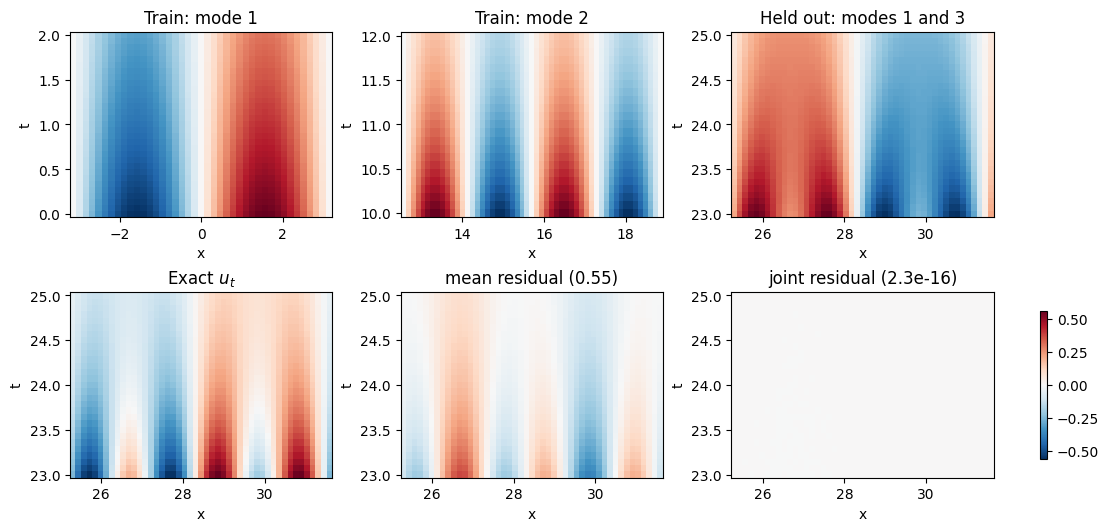

In [17]:
def reaction_diffusion(nt, nx, start, left, modes):
    t = np.linspace(start, start + 2, nt)
    x = np.linspace(left, left + 2 * np.pi, nx)
    T, X = np.meshgrid(t - start, x, indexing="ij")
    u, ut, ux, uxx = (np.zeros_like(T) for _ in range(4))
    for k, amplitude in modes:
        decay = amplitude * np.exp(-(0.2 + 0.1 * k**2) * T)
        mode = decay * np.sin(k * X)
        u += mode
        ut -= (0.2 + 0.1 * k**2) * mode
        ux += k * decay * np.cos(k * X)
        uxx -= k**2 * mode
    return t, x, {"u": u, "du/dx0": ut, "du/dx1": ux, "d^2u/dx1^2": uxx, "1": 1.0}

samples = [
    reaction_diffusion(31, 41, 0.0, -np.pi, [(1, 1.0)]),
    reaction_diffusion(23, 53, 10.0, 4 * np.pi, [(2, 0.7)]),
    reaction_diffusion(29, 47, 23.0, 8 * np.pi + 0.17, [(1, 0.8), (3, 0.4)]),
]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.2), layout="constrained")
for ax, (t, x, fields), title in zip(
        axes[0], samples, ["Train: mode 1", "Train: mode 2", "Held out: modes 1 and 3"]):
    ax.pcolormesh(x, t, fields["u"], shading="auto", cmap="RdBu_r")
    ax.set(title=title, xlabel="x", ylabel="t")

t, x, held_out = samples[-1]
target = held_out["du/dx0"]
scale = np.abs(target).max()
fields = {"Exact $u_t$": target}
for mode, weights in data["reaction_diffusion_coefficients"].items():
    residual = target - sum(value * held_out[term] for term, value in weights.items())
    relative = np.linalg.norm(residual) / np.linalg.norm(target)
    fields[f"{mode} residual ({relative:.2g})"] = residual
for ax, (title, field) in zip(axes[1], fields.items()):
    mesh = ax.pcolormesh(x, t, field, shading="auto", cmap="RdBu_r", vmin=-scale, vmax=scale)
    ax.set(title=title, xlabel="x", ylabel="t")
fig.colorbar(mesh, ax=axes[1], shrink=0.8)
plt.show()

## Robot heading

Use robot index 3 from the 30-robot recording. Let $u=\cos\varphi$ and $v=\sin\varphi$. Six two-second windows from the first minute train the model. Six windows from the second minute are held out. The slope of unwrapped phase over the first minute gives a reference spin rate. Contacts can change the instantaneous rate.

,stage,mode,seed,status,exact_support,exact_on_front,coefficient_error,holdout_residual,equation
0,discovery,joint,0,ok,False,True,0.0418,0.311,-4.365735061213712 * v{power: 1.0} + 0.16959314995851058 = du/dx0{power: 1.0} | 4.3251185826386305 * u{pow...
1,discovery,joint,1,ok,False,True,0.0418,0.311,-4.365735061213712 * v{power: 1.0} + 0.16959314995851058 = du/dx0{power: 1.0} | 4.3251185826386305 * u{pow...
2,discovery,joint,2,ok,False,True,0.0418,0.311,-4.365735061213712 * v{power: 1.0} + 0.16959314995851058 = du/dx0{power: 1.0} | 4.3251185826386305 * u{pow...
3,discovery,joint,3,ok,False,True,0.0418,0.311,-4.365735061213712 * v{power: 1.0} + 0.16959314995851058 = du/dx0{power: 1.0} | 4.3251185826386305 * u{pow...
4,discovery,joint,4,ok,False,True,0.0418,0.311,-4.365735061213712 * v{power: 1.0} + 0.16959314995851058 = du/dx0{power: 1.0} | 4.3251185826386305 * u{pow...
5,discovery,mean,0,ok,False,True,0.0437,0.312,-4.407791970427151 * v{power: 1.0} + 0.15798517134076884 = du/dx0{power: 1.0} | 4.328474831875724 * u{powe...
6,discovery,mean,1,ok,False,True,0.0437,0.312,-4.407791970427151 * v{power: 1.0} + 0.15798517134076884 = du/dx0{power: 1.0} | 4.328474831875724 * u{powe...
7,discovery,mean,2,ok,False,True,0.0437,0.312,-4.407791970427151 * v{power: 1.0} + 0.15798517134076884 = du/dx0{power: 1.0} | 4.328474831875724 * u{powe...
8,discovery,mean,3,ok,False,True,0.0437,0.312,-4.407791970427151 * v{power: 1.0} + 0.15798517134076884 = du/dx0{power: 1.0} | 4.328474831875724 * u{powe...
9,discovery,mean,4,ok,False,True,0.0437,0.312,-4.407791970427151 * v{power: 1.0} + 0.15798517134076884 = du/dx0{power: 1.0} | 4.328474831875724 * u{powe...


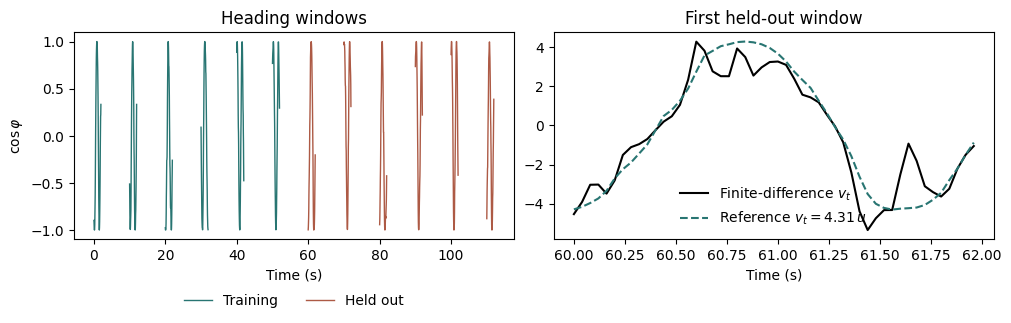

In [18]:
robot_runs = runs.loc[runs["scenario"].eq("robot_heading")]
columns = ["stage", "mode", "seed", "status", "exact_support", "exact_on_front",
           "coefficient_error", "holdout_residual", "equation"]
with pd.option_context("display.max_colwidth", 110, "display.float_format", "{:.3g}".format):
    display(robot_runs[columns].sort_values(["stage", "mode", "seed"]).reset_index(drop=True))

windows = data["robot_windows"]
omega = data["reference_spin_rate"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.1), layout="constrained")
for split, name, color in [("train", "Training", "#287572"), ("holdout", "Held out", "#ad5a45")]:
    records = [record for record in windows if record["split"] == split]
    for index, record in enumerate(records):
        axes[0].plot(record["time"], record["phase_cosine"], color=color, lw=1,
                     label=name if index == 0 else None)
axes[0].set(xlabel="Time (s)", ylabel=r"$\cos\varphi$", title="Heading windows")
axes[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2)
record = next(record for record in windows if record["split"] == "holdout")
t = np.array(record["time"])
axes[1].plot(t, np.gradient(record["phase_sine"], t), color="black", label=r"Finite-difference $v_t$")
axes[1].plot(t, omega * np.asarray(record["phase_cosine"]), "--", color=colors["joint"],
             label=rf"Reference $v_t={omega:.2f}\,u$")
axes[1].set(xlabel="Time (s)", title="First held-out window")
axes[1].legend(frameon=False)
plt.show()

## Findings

- Joint fitting helps most when terms are proportional within each record but independent across records. The single-mode reaction–diffusion, overdamped oscillator, and Klein–Gordon runs illustrate this with exact derivatives. The wave equation can be recovered with its shorter reference structure.
- With noisy measurements, correct structure does not guarantee accurate coefficients. Weak-form fits improve some second-order cases. Joint repair still struggles on noisy records that only identify the law when pooled.
- Model selection matters. On the recorded synthetic fronts, the jackknife rule recovered 189 correct structures out of 240, compared with 123 for discrepancy alone. A correct structure appeared on 205 fronts.
- With the robot structure supplied, the two modes estimate roughly $4.33\,\mathrm{rad/s}$ from $v_t$. The training-phase reference is about $4.31\,\mathrm{rad/s}$. Short windows can favor a small intercept during discovery.